`[Cell 1]`

# Question B: baselines

Three simple forecasts that LightGBM and XGBoost must beat. If a complex model cannot beat a simple rule, it is not adding value.

| Baseline | Forecast for zone *z* at hour *h* | Inputs |
|---|---|---|
| **B1: seasonal naive** | The same zone's AC load at the same hour **one week earlier** | last week's load |
| **B2: average profile** | The **average** training load for that **zone, hour and day type** (weekday / weekend / holiday) | zone, hour, day type |
| **B3: calendar + AC lags** | A **linear regression** on the calendar features and the AC lags | hour, weekday, month, weekend, holiday, zone, floor, and the load yesterday, 2 days ago and last week |

**How they are tested** (the same splits as the models):

- **Validation:** B2 and B3 are fitted on the `train` rows and scored on the `validation` rows (April, August, December 2019).
- **Test:** B2 and B3 are refitted on all of 2019 (`train` + `validation`) and scored **once** on the `test` rows (July–September 2018).
- All three baselines are scored on **the same rows**: hours where every baseline can make a forecast. (The modelling dataset only contains hours where the AC load is known.)
- Accuracy is reported for **all hours** and for **operating hours only** (`is_operating_hours`: weekdays that are not holidays, 07:00–17:00).

**Input:** `../cleaned_data/question_b_model_data.parquet` (from `../cleaned_data/02_build_model_dataset.ipynb`).
**Outputs:** `question_b_baseline_results.csv` (this folder), `../cleaned_data/question_b_baseline_predictions.parquet`, and the charts `baseline_forecast_vs_actual_*.png`, `baseline_wape.png`.

In [1]:
# [Cell 2]
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 250)

data = pd.read_parquet('../cleaned_data/question_b_model_data.parquet')
print(data.shape)
data['split'].value_counts()

(209119, 35)


split
train         111779
test           50567
validation     46773
Name: count, dtype: int64

`[Cell 3]`

## 1. The accuracy measures

For every forecast, error = actual − forecast. Over all the hours scored:

| Measure | Formula | Meaning | Better |
|---|---|---|---|
| **MAE** | mean of \|error\| | the typical size of the error, in kW | lower |
| **RMSE** | √(mean of error²) | like MAE, but large errors count more | lower |
| **CV(RMSE)** | RMSE ÷ mean actual × 100 | RMSE as a % of the average load | lower |
| **NMBE** | sum of errors ÷ (n × mean actual) × 100 | the average bias, in %: **positive = forecasts too low**, negative = too high (the ASHRAE Guideline 14 convention) | close to 0 |
| **WAPE** | sum of \|error\| ÷ sum of actual × 100 | total error as a % of total load | lower |

In [2]:
# [Cell 4]
def accuracy(actual, forecast):
    """The five accuracy measures for one set of forecasts."""
    actual, forecast = np.asarray(actual, float), np.asarray(forecast, float)
    error = actual - forecast
    mean_actual = actual.mean()
    rmse = np.sqrt(np.mean(error ** 2))
    return {
        'n_hours': len(actual),
        'MAE (kW)': np.mean(np.abs(error)),
        'RMSE (kW)': rmse,
        'CV(RMSE) (%)': rmse / mean_actual * 100,
        'NMBE (%)': error.sum() / (len(actual) * mean_actual) * 100,
        'WAPE (%)': np.abs(error).sum() / np.abs(actual).sum() * 100,
    }

`[Cell 5]`

## 2. The three baselines

Each baseline is a function: it is given the rows to **learn from** (`fit`) and the rows to **forecast** (`predict`), and returns one forecast per row to forecast. Rows it cannot forecast are left as `NaN`.

- **B1** needs nothing to learn from: the forecast is the `ac_load_kw_last_week` column.
- **B2** works out the average load for every zone × hour × day type in `fit`. A holiday combination with no training data falls back to the zone's **weekend** average at that hour (a closed office behaves like a weekend).
- **B3** fits a linear regression. `hour`, `weekday` and the zone are turned into yes/no columns (one per value), because their numbers are labels, not amounts. `month` is kept as a **number**: the validation months (April, August, December) never appear in its training months, and as a number April can sit between March and May. A linear regression cannot use rows with a missing lag, so those rows are left out of its fitting and get no forecast. A straight-line model can also forecast **below 0 kW** (impossible for an AC load), so negative forecasts are set to 0.

In [3]:
# [Cell 6]
def b1_seasonal_naive(fit, predict):
    return predict['ac_load_kw_last_week']


def b2_average_profile(fit, predict):
    known = fit
    profile = known.groupby(['zone_id', 'hour', 'day_type'])['ac_load_kw'].mean()
    weekend = known[known['day_type'] == 'weekend'].groupby(['zone_id', 'hour'])['ac_load_kw'].mean()

    keys = pd.MultiIndex.from_frame(predict[['zone_id', 'hour', 'day_type']])
    forecast = pd.Series(profile.reindex(keys).to_numpy(), index=predict.index)
    fallback = pd.Series(weekend.reindex(pd.MultiIndex.from_frame(predict[['zone_id', 'hour']])).to_numpy(),
                         index=predict.index)
    holiday_gap = forecast.isna() & (predict['day_type'] == 'holiday')
    return forecast.where(~holiday_gap, fallback)


B3_NUMBERS = ['month', 'is_weekend', 'is_holiday', 'floor',
              'ac_load_kw_yesterday', 'ac_load_kw_2_days_ago', 'ac_load_kw_last_week']
B3_LABELS = ['hour', 'weekday', 'zone_id']           # turned into yes/no columns


def b3_inputs(rows):
    labels = pd.get_dummies(rows[B3_LABELS].astype(str), dtype=float)
    return pd.concat([rows[B3_NUMBERS].astype(float), labels], axis=1)


def b3_linear_regression(fit, predict):
    lags = ['ac_load_kw_yesterday', 'ac_load_kw_2_days_ago', 'ac_load_kw_last_week']
    learn = fit[fit[lags].notna().all(axis=1)]
    x_learn = b3_inputs(learn)
    model = LinearRegression().fit(x_learn, learn['ac_load_kw'])

    usable = predict[lags].notna().all(axis=1)
    x_predict = b3_inputs(predict[usable]).reindex(columns=x_learn.columns, fill_value=0.0)
    forecast = pd.Series(np.nan, index=predict.index)
    forecast[usable] = model.predict(x_predict).clip(min=0)     # AC load cannot be negative
    return forecast


BASELINES = {'B1 seasonal naive': b1_seasonal_naive,
             'B2 average profile': b2_average_profile,
             'B3 calendar + AC lags': b3_linear_regression}

`[Cell 7]`

## 3. Make the forecasts

- **Validation:** learn from `train`, forecast `validation`.
- **Test:** learn from `train` + `validation` (all of 2019), forecast `test`.

In [4]:
# [Cell 8]
periods = {
    'validation': (data[data['split'] == 'train'], data[data['split'] == 'validation']),
    'test': (data[data['split'].isin(['train', 'validation'])], data[data['split'] == 'test']),
}

predictions = []
for period, (fit, predict) in periods.items():
    table = predict[['zone_id', 'timestamp', 'split', 'is_operating_hours', 'ac_load_kw']].copy()
    table.insert(2, 'period', period)
    for name, baseline in BASELINES.items():
        table[name] = baseline(fit, predict)
    predictions.append(table)
predictions = pd.concat(predictions, ignore_index=True)

# the rows every baseline can be scored on: a forecast from all three
baseline_names = list(BASELINES)
predictions['scored'] = predictions[baseline_names].notna().all(axis=1).astype(int)

predictions.groupby('period').agg(rows=('scored', 'size'), scored=('scored', 'sum'))

,rows,scored
period,,
test,50567,46064
validation,46773,45931


`[Cell 9]`

## 4. Accuracy table

For each period, baseline and set of hours. **The headline numbers are the test rows (July–September 2018).**

In [5]:
# [Cell 10]
scored = predictions[predictions['scored'] == 1]
rows = []
for period in ['validation', 'test']:
    in_period = scored[scored['period'] == period]
    for hours, subset in [('all hours', in_period),
                          ('operating hours', in_period[in_period['is_operating_hours'] == 1])]:
        for name in baseline_names:
            rows.append({'period': period, 'hours': hours, 'baseline': name,
                         **accuracy(subset['ac_load_kw'], subset[name])})
results = pd.DataFrame(rows)
results.round(2)

,period,hours,baseline,n_hours,MAE (kW),RMSE (kW),CV(RMSE) (%),NMBE (%),WAPE (%)
0,validation,all hours,B1 seasonal naive,45931,1.76,5.63,130.64,0.13,40.88
1,validation,all hours,B2 average profile,45931,1.08,2.86,66.30,-2.84,25.16
2,validation,all hours,B3 calendar + AC lags,45931,1.90,4.15,96.28,-5.94,44.17
3,validation,operating hours,B1 seasonal naive,11848,3.88,7.60,49.95,12.79,25.47
4,validation,operating hours,B2 average profile,11848,2.63,3.89,25.53,-1.84,17.30
5,validation,operating hours,B3 calendar + AC lags,11848,3.56,5.92,38.91,11.82,23.37
6,test,all hours,B1 seasonal naive,46064,1.20,4.15,98.18,-1.27,28.33
7,test,all hours,B2 average profile,46064,1.15,3.00,71.00,-7.76,27.11
8,test,all hours,B3 calendar + AC lags,46064,1.67,3.40,80.47,-12.11,39.58
9,test,operating hours,B1 seasonal naive,12602,2.31,4.77,34.87,4.70,16.92


`[Cell 11]`

## 5. Accuracy by zone (test, operating hours)

WAPE for each zone. Zones differ a lot in size and behaviour, so this shows where each baseline struggles.

In [6]:
# [Cell 12]
test_operating = predictions[(predictions['period'] == 'test') & (predictions['scored'] == 1)
                             & (predictions['is_operating_hours'] == 1)]
by_zone = pd.DataFrame({
    name: test_operating.groupby('zone_id').apply(lambda g: accuracy(g['ac_load_kw'], g[name])['WAPE (%)'],
                                                  include_groups=False)
    for name in baseline_names
}).round(1)
by_zone['best'] = by_zone.idxmin(axis=1)
by_zone

,B1 seasonal naive,B2 average profile,B3 calendar + AC lags,best
zone_id,,,,
F2_Z1,15.3,12.3,17.5,B2 average profile
F2_Z2,20.5,38.2,17.2,B3 calendar + AC lags
F2_Z4,8.2,15.1,12.8,B1 seasonal naive
F3_Z1,11.7,9.0,14.3,B2 average profile
F3_Z2,15.4,13.4,15.1,B2 average profile
F3_Z4,20.1,26.9,19.4,B3 calendar + AC lags
F3_Z5,21.0,16.7,22.7,B2 average profile
F4_Z1,13.0,17.7,13.6,B1 seasonal naive
F4_Z2,15.6,21.0,14.8,B3 calendar + AC lags


`[Cell 13]`

## 6. Charts: forecast vs actual

One week for Floor 2 zone 2 (the largest zone), in each period: the actual AC load (black) and each baseline's forecast.

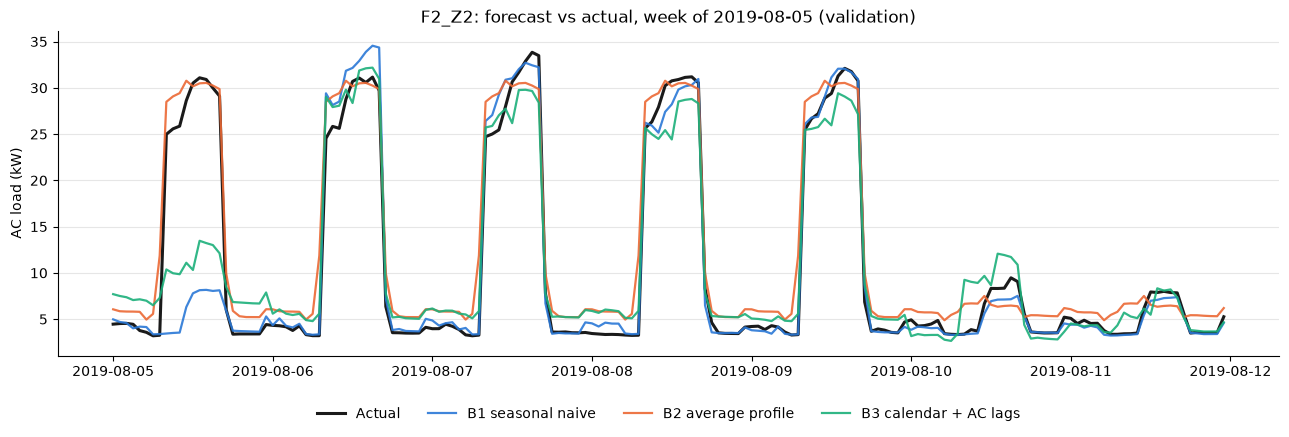

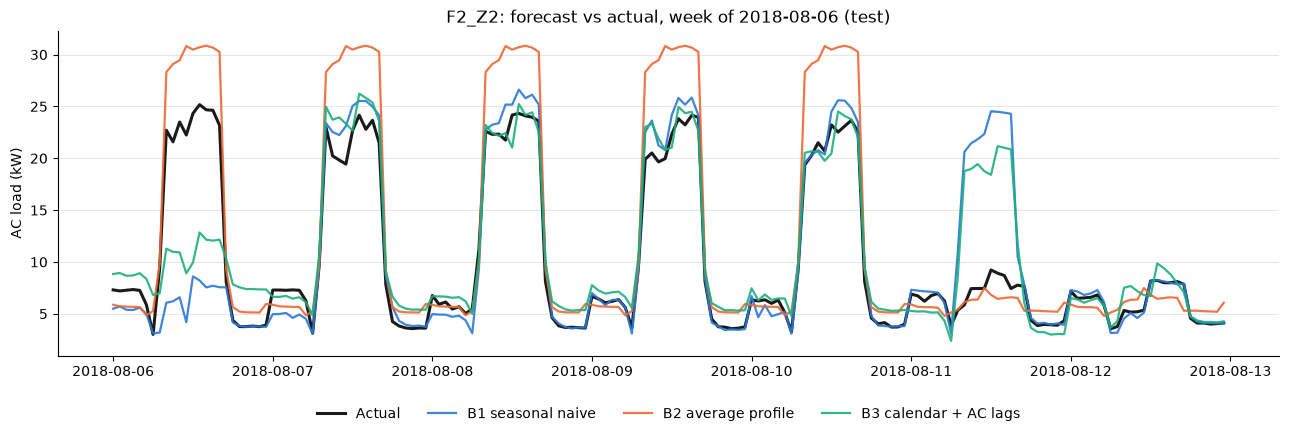

In [7]:
# [Cell 14]
COLOURS = {'B1 seasonal naive': '#2a78d6', 'B2 average profile': '#eb6834', 'B3 calendar + AC lags': '#1baf7a'}


def plot_week(zone, start, period, filename):
    end = pd.Timestamp(start) + pd.Timedelta(days=7)
    week = predictions[(predictions['zone_id'] == zone) & (predictions['period'] == period)
                       & (predictions['timestamp'] >= start) & (predictions['timestamp'] < end)]
    fig, ax = plt.subplots(figsize=(13, 4.5))
    ax.plot(week['timestamp'], week['ac_load_kw'], color='0.1', lw=2.2, label='Actual')
    for name in baseline_names:
        ax.plot(week['timestamp'], week[name], color=COLOURS[name], lw=1.6, alpha=0.9, label=name)
    ax.set(ylabel='AC load (kW)', title=f'{zone}: forecast vs actual, week of {start} ({period})')
    ax.grid(axis='y', color='0.9')
    ax.spines[['top', 'right']].set_visible(False)
    ax.legend(frameon=False, ncol=4, loc='upper center', bbox_to_anchor=(0.5, -0.12))
    fig.tight_layout()
    fig.savefig(filename, dpi=130, bbox_inches='tight')
    plt.show()


plot_week('F2_Z2', '2019-08-05', 'validation', 'baseline_forecast_vs_actual_validation.png')
plot_week('F2_Z2', '2018-08-06', 'test', 'baseline_forecast_vs_actual_test.png')

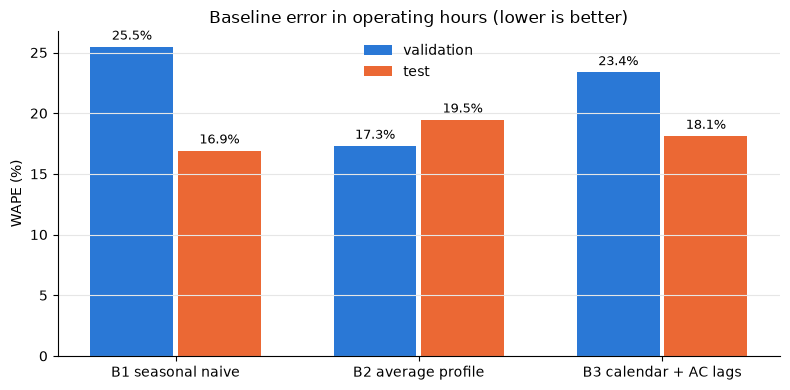

In [8]:
# [Cell 15]
# WAPE of each baseline, operating hours, validation and test
chart = results[results['hours'] == 'operating hours'].pivot(index='baseline', columns='period', values='WAPE (%)')
chart = chart[['validation', 'test']]
fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(chart))
for i, (period, colour) in enumerate([('validation', '#2a78d6'), ('test', '#eb6834')]):
    bars = ax.bar(x + (i - 0.5) * 0.36, chart[period], width=0.34, color=colour, label=period)
    ax.bar_label(bars, fmt='%.1f%%', padding=3, fontsize=9)
ax.set_xticks(x, chart.index)
ax.set(ylabel='WAPE (%)', title='Baseline error in operating hours (lower is better)')
ax.grid(axis='y', color='0.9')
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig('baseline_wape.png', dpi=130, bbox_inches='tight')
plt.show()

`[Cell 16]`

## 7. Save

- `question_b_baseline_results.csv`: the accuracy table.
- `../cleaned_data/question_b_baseline_predictions.parquet`: every forecast, row by row (zone, hour, period, actual, B1, B2, B3, and `scored` = 1 on the rows used in the accuracy table). The LightGBM and XGBoost models can be compared with the baselines on the same rows (for example with the Diebold–Mariano test).

In [9]:
# [Cell 17]
results.to_csv('question_b_baseline_results.csv', index=False)
predictions.to_parquet('../cleaned_data/question_b_baseline_predictions.parquet', index=False)
print('saved:', results.shape, predictions.shape)

saved: (12, 9) (97340, 10)
